# Glasauer & Shi (2021 data): two-state model versus the three-state model (Section 5.5, Appendix C)

This notebook asks one narrow question: **if both models are fitted to the randomized condition, can they predict
the change produced solely by putting the same durations into random-walk order?**

The comparison follows the evidence order of Glasauer and Shi (2022):

1. central tendency (CT);
2. lag-1 serial dependence (SD);
3. the randomized-condition partial-correlation check;
4. duration-resolved data–model correspondence and $R^2$;
5. the held-out comparison on the random-walk responses;
6. which parameters change between the two sequence types when the three-state model is fitted to each.

Model curves are deterministic trial-wise predictions, and every error bar is **SEM across participants**, as in the
original paper. The three-state model is the observer of Section 5 (`three_state_kalman.ipynb`) with the response-bias
level **B2**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sdu.reports import plots as P
from sdu.reports import glasauer_shi as R

P.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")
D = R.Data()
print(f"{len(D.participants)} participants; 400 trials per condition before invalid responses are masked")

14 participants; 400 trials per condition before invalid responses are masked


## 1. Models

**Two-state model (Glasauer & Shi, 2022).** Duration is encoded as $z_i=\log(1+d_i/d_0)$, with $d_0=.1$ s. The
transition and measurement equations are

$$
\mathbf F=\begin{pmatrix}0&1\\0&1\end{pmatrix},\qquad
\mathbf Q=\begin{pmatrix}v&0\\0&q\end{pmatrix},\qquad
\mathbf H=(1,0),
$$

and the authors' code decodes the estimate as

$$\hat d_i=d_0\left[\exp(\hat x_i+\Delta x)-1\right].$$

Its three fitted quantities are $v/r$, $q/r$, and $\Delta x$. We fit them by trial-wise least squares, separately
for each participant, from the randomized condition only (`scripts/model/glasauer_shi/fit_two_state.py`).

**Three-state model.** The model selected for our Experiment 1, C3-S0-B2, applied unchanged. This design has no
coherence manipulation, so every C and S level reduces to the same model: the coherence ratios multiply by 1, there
are no switches, and only one of $\phi^L$, $\phi^H$ is ever used. What remains is the three-state filter with a single
readout retention $\phi$ and the latent response bias B2 (seven free parameters):

$$
\mathbf F=\begin{bmatrix}0&1&0\\0&1&0\\0&0&\lambda\end{bmatrix},\qquad
\hat u_i=\hat x_i+\big(1-K_i^{(x)}\big)\,\phi\,\hat f_{i-1},\qquad
y_i=\hat u_i+b_i+d_0+\varepsilon_i,\qquad b_i=\lambda b_{i-1}+\eta_i ,
$$

with the state $\mathbf s_i=[\hat x_i,\hat m_i,\hat b_i]^\top$, $\mathbf Q=\operatorname{diag}(q_1,q_2,q_3)$, the
measurement $z_i=s_i$ (the presented duration) and $\mathbf H=[1,0,0]$; $\hat f_{i-1}=\hat x_{i-1}-\hat m_{i-1}$ is the
previous fast deviation, and $\phi=0$ is the nested model without retention. The comparison model,
**three-state B0 (no bias state)**, removes the bias.

For both models, the fitted randomized parameters are frozen before the random-walk stimulus sequence is supplied.
The random-walk responses therefore never enter the model fits.

In [2]:
participant_statistics = R.participant_statistics(D)

## 2. CT and SD

CT is $1-$ the slope of reproduction on current duration. SD is the slope of current reproduction error on the
previous duration. These are the paper's simple-regression definitions. In the randomized condition, the paper
additionally checks $r(e_i,s_{i-1}\mid s_i)$ and the reverse partial correlation. In the random-walk condition,
$s_i$ and $s_{i-1}$ are intentionally highly autocorrelated; the paper does not estimate controlled CT/SD there.
Instead, it asks whether parameters fitted to randomized trials predict the random-walk CT/SD pattern. Lag 2 is
reported later as a supplementary check.

The figure below is the analogue of the paper's condition summary: participant means $\pm$ participant-level SEM.
It is not a posterior-predictive interval.

CT             SD       
                             mean    sem    mean    sem
condition   model                                      
random walk data           0.0960 0.0370 -0.0860 0.0370
            three-state B2 0.0910 0.0270 -0.0840 0.0270
            two-state      0.0140 0.0380 -0.0060 0.0380
randomized  data           0.4550 0.0460  0.1090 0.0150
            three-state B2 0.4520 0.0460  0.1110 0.0140
            two-state      0.4390 0.0480  0.0950 0.0180

,mean,std,t(13),p
measure,,,,
"partial r(error, previous | current)",0.1966,0.0703,10.4558,<.0001
"partial r(error, current | previous)",-0.6025,0.1559,-14.4599,<.0001


,mean,min,max
condition,,,
random walk,0.9920,0.9850,0.9940
randomized,0.0180,-0.0910,0.0470


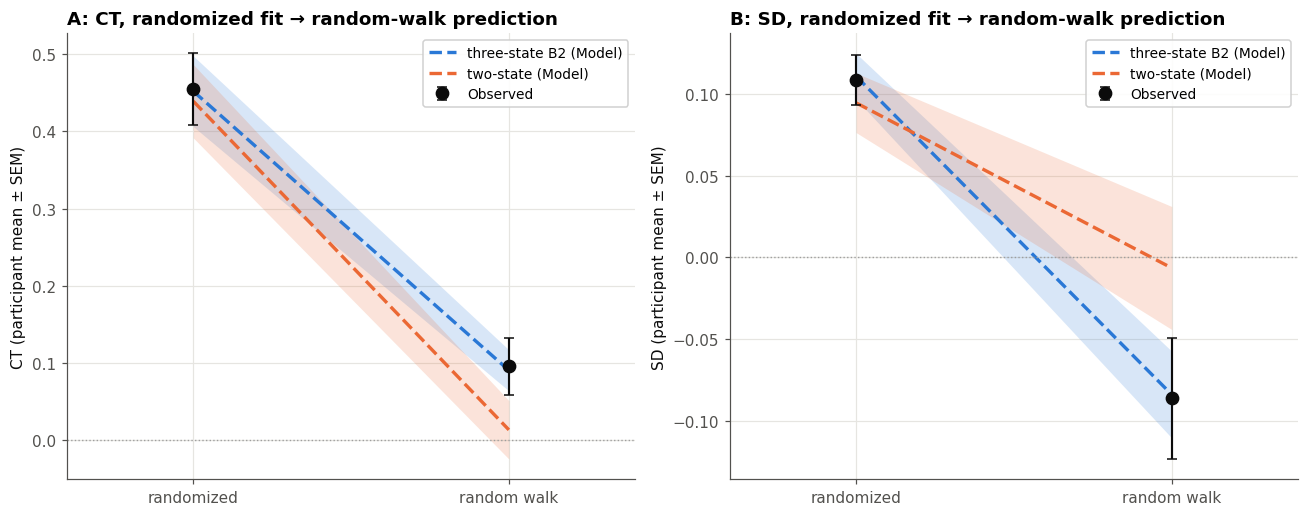

model − data  SEM of difference   t(13)      p
model          measure                                                
two-state      CT            -0.0820             0.0480 -1.7230 0.1090
               SD             0.0800             0.0480  1.6570 0.1220
three-state B2 CT            -0.0050             0.0420 -0.1230 0.9040
               SD             0.0020             0.0420  0.0540 0.9580

,randomized,random walk,t(13),p,randomized > random walk
measure,,,,,
CT,0.4549,0.0958,7.2913,0.0000,14/14
SD,0.1087,-0.0863,5.1563,0.0002,13/14


In [3]:
display(R.ct_sd_summary(participant_statistics))
display(R.partial_correlations(participant_statistics))
display(R.predictor_correlation(participant_statistics))
R.plot_ct_sd(participant_statistics)
plt.show()
display(R.random_walk_prediction_tests(participant_statistics))
display(R.condition_tests(participant_statistics))

**Reading.**

* <span style="color:#b71c1c">**The sequence type changes CT and SD strongly.** CT falls from .455 (randomized) to
  .096 (random walk), $t(13)=7.29$, $p<.001$, in 14 of 14 participants. SD changes sign, from .109 to $-.086$,
  $t(13)=5.16$, $p<.001$, in 13 of 14 participants.</span>
* In random walk, the current and previous durations correlate at .99, so these simple-regression slopes mainly
  reflect the stimulus order. The paper's point is that the change follows from the order alone, with the observer's
  parameters unchanged.
* <span style="color:#b71c1c">With every randomized-fitted parameter frozen, **the three-state model predicts the random-walk
  CT and SD** (.091 and $-.084$ against .096 and $-.086$, paired $p=.90$ and $.96$). The two-state model does not
  (.014 and $-.006$).</span>

## 3. Duration-resolved correspondence

For every participant, error is averaged within the paper's 0.1-s duration bins. Those participant curves are then
averaged; the bars and ribbons are SEM across participants at each bin. There are no simulated cohorts and no
quantile bands.

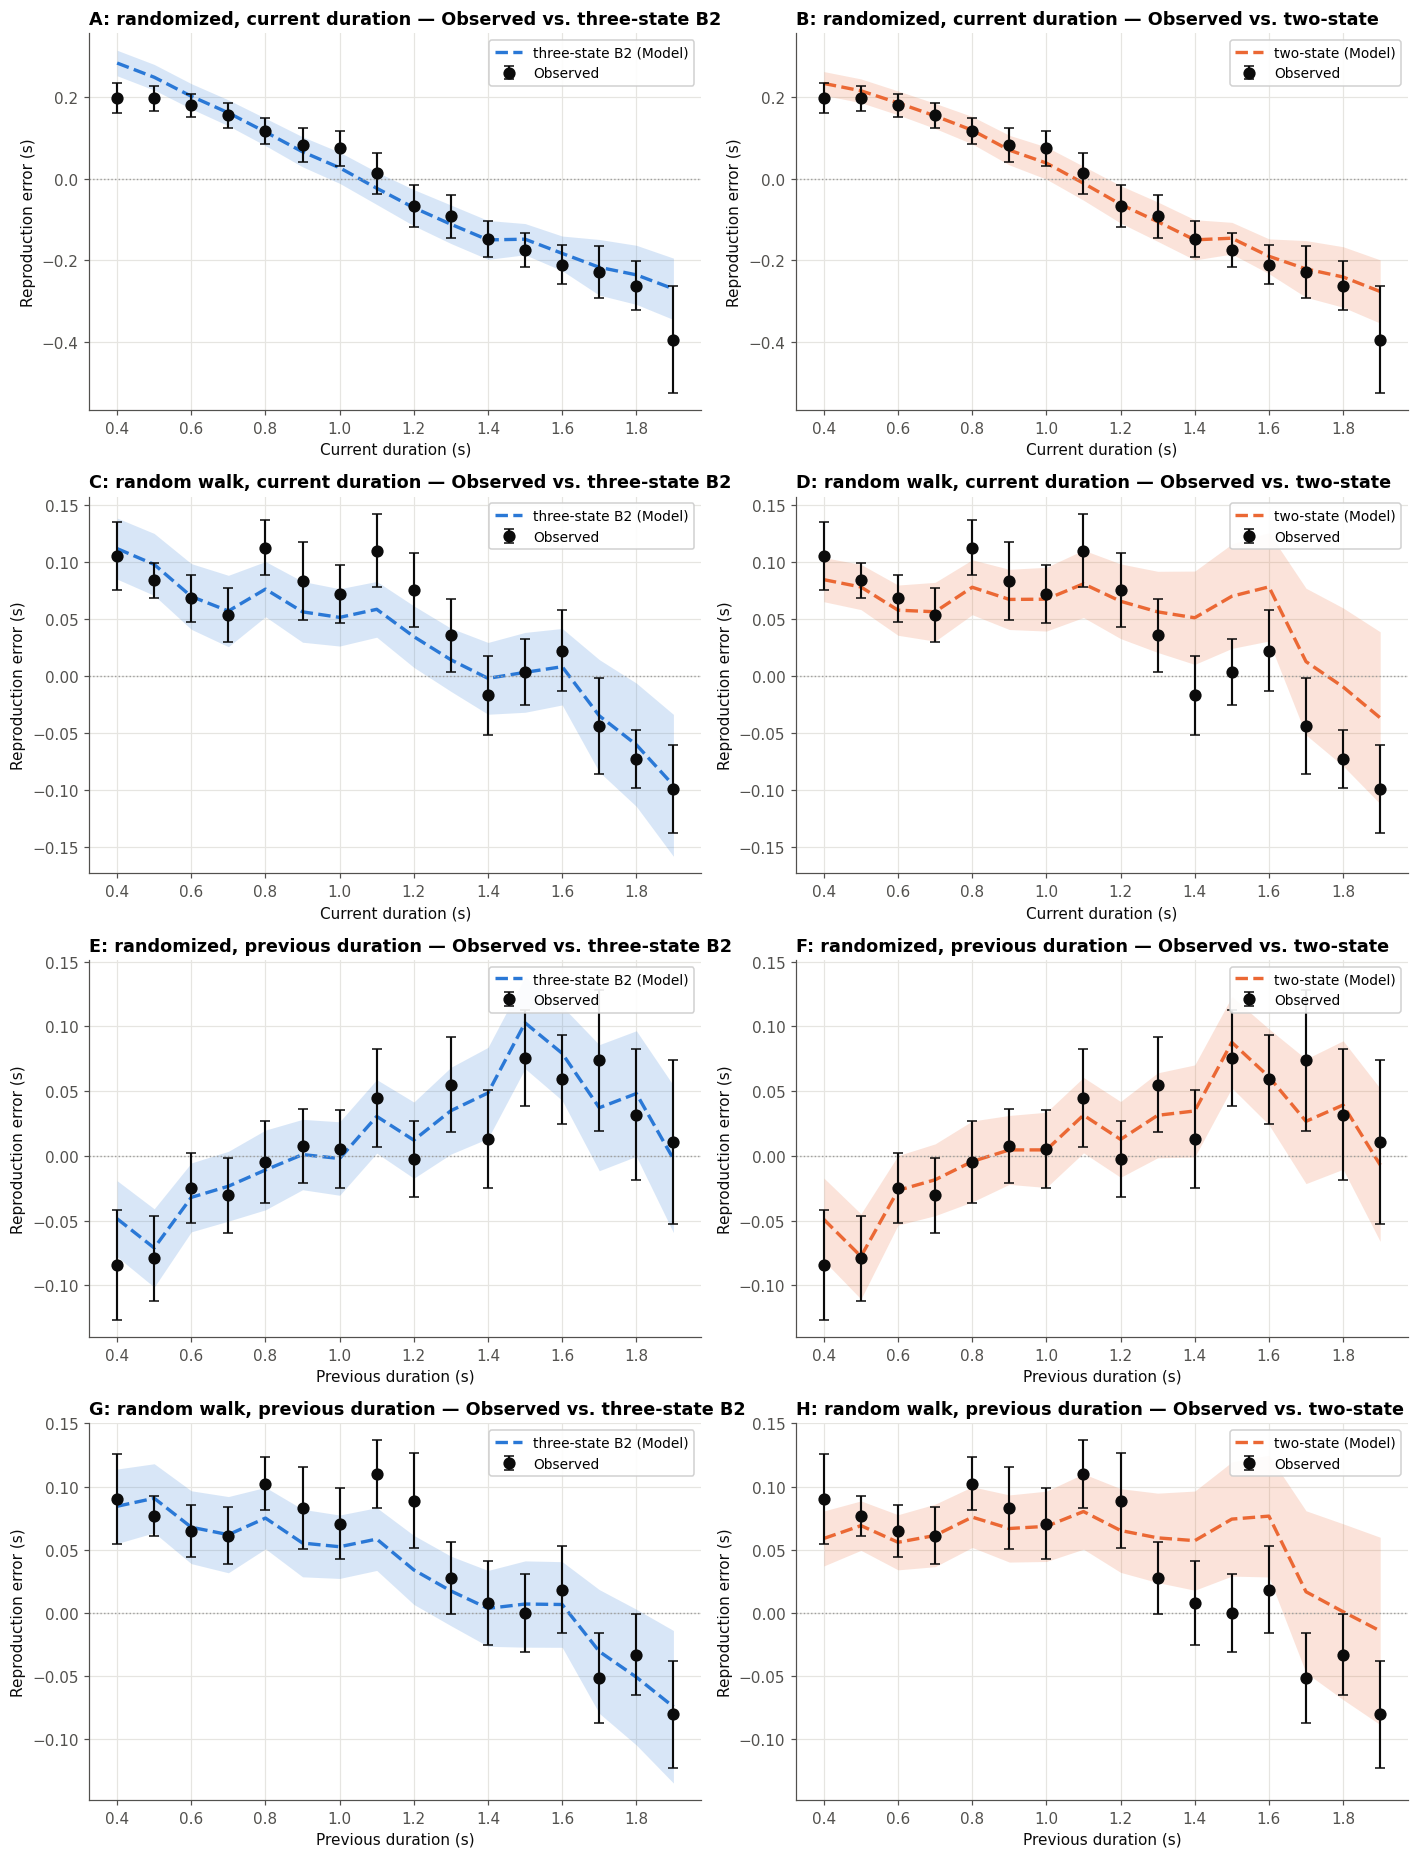

condition                         random walk  randomized
model          curve                                     
three-state B2 current duration        0.8750      0.9380
               lag-2 duration          0.6930      0.8540
               previous duration       0.8230      0.8090
two-state      current duration        0.5920      0.9630
               lag-2 duration          0.3640      0.7830
               previous duration       0.4830      0.8390

In [4]:
curves = R.duration_curves(D)
R.plot_duration_curves(curves)
plt.show()
display(R.r_squared_table(curves))

For reference, the paper reports $R^2=(.964,.803,.834)$ for current, lag 1, and lag 2 in the randomized condition,
and $(.629,.544,.428)$ for the frozen-parameter random-walk prediction. The table above is recomputed from the
public CSV and the supplied model code; it reproduces the same pattern but is not silently replaced by the published
numbers where the numerical values differ.

### Lag 2 (supplementary)

Lag 2 is retained in the $R^2$ table because iterative models predict it, but it is not used to decide whether the
main CT/SD transfer worked. The primary comparison is current duration and lag 1.

## 4. Participant-level held-out comparison

Group-average $R^2$ is descriptive. The stronger test fits randomized trials only, freezes every parameter, and
scores each participant's random-walk responses. The fits used 24 optimization starts plus a start at $\phi=0$,
for the three-state model and for its ablation without the bias state (`scripts/model/glasauer_shi/fit_transfer.py`,
`compare_transfer.py`). It reports:

- trial-level RMSE of the predictive mean;
- mean log predictive density, which evaluates both location and uncertainty;
- absolute CT and SD prediction errors.

Differences are the three-state model minus the comparator. Negative values favor it for RMSE and absolute errors; positive
values favor it for log score. Confidence intervals bootstrap participants, and the $p$ value is an exact two-sided
participant-level sign-flip test ($2^{14}$ assignments).

In [5]:
comparison, means = R.transfer_tables()
display(comparison)
display(means)

preferred  \
comparator                     metric                        
two-state                      trial-level RMSE      lower   
                               mean log score       higher   
                               absolute CT error     lower   
                               absolute SD error     lower   
three-state B0 (no bias state) trial-level RMSE      lower   
                               mean log score       higher   
                               absolute CT error     lower   
                               absolute SD error     lower   

                                                  three-state B2 − comparator  \
comparator                     metric                                           
two-state                      trial-level RMSE                       -0.0013   
                               mean log score                          0.0840   
                               absolute CT error                      -0.0271   
                               absolute SD error                      -0.0247   
three-state B0 (no bias state) trial-level RMSE                        0.0013   
                               mean log score                          0.0722   
                               absolute CT error                       0.0099   
                               absolute SD error                       0.0099   

                                                  95% CI low  95% CI high  \
comparator                     metric                                       
two-state                      trial-level RMSE      -0.0089       0.0064   
                               mean log score         0.0298       0.1483   
                               absolute CT error     -0.0808       0.0274   
                               absolute SD error     -0.0809       0.0317   
three-state B0 (no bias state) trial-level RMSE      -0.0007       0.0043   
                               mean log score         0.0264       0.1265   
                               absolute CT error     -0.0034       0.0312   
                               absolute SD error     -0.0034       0.0313   

                                                  exact p  \
comparator                     metric                       
two-state                      trial-level RMSE    0.7502   
                               mean log score      0.0088   
                               absolute CT error   0.3655   
                               absolute SD error   0.4242   
three-state B0 (no bias state) trial-level RMSE    0.4963   
                               mean log score      0.0074   
                               absolute CT error   0.4705   
                               absolute SD error   0.4753   

                                                  participants favoring three-state B2  
comparator                     metric                                                   
two-state                      trial-level RMSE                                      9  
                               mean log score                                       11  
                               absolute CT error                                     9  
                               absolute SD error                                     8  
three-state B0 (no bias state) trial-level RMSE                                      8  
                               mean log score                                       13  
                               absolute CT error                                     7  
                               absolute SD error                                     8

,trial-level RMSE,mean log score,absolute CT error,absolute SD error
model,,,,
three-state B0 (no bias state),0.1913,0.2190,0.1083,0.1096
three-state B2,0.1926,0.2912,0.1181,0.1195
two-state,0.1939,0.2072,0.1453,0.1442


**Reading.**

* <span style="color:#b71c1c">**Against the paper two-state model.** The three-state model has the better held-out log score: $+.084$,
  95% CI $[.030,.148]$, exact $p=.009$, 11 of 14 participants.</span> RMSE and the absolute CT and SD errors do not
  differ (CIs include 0, $p\ge.37$).
* <span style="color:#b71c1c">**Against the matched ablation without the bias state.** The bias state improves the log score by $.072$,
  95% CI $[.026,.127]$, $p=.007$, 13 of 14 participants.</span> The point-prediction metrics do not differ.
* The third state therefore helps the predictive response distribution, not the trial-wise mean.

### In-sample AIC on the randomized condition

Both models are fitted to the same randomized trials (the paper model is fitted only to this condition), and both
log-likelihoods are in seconds. The two-state model has $k=4$ ($v/r$, $q/r$, $\Delta x$, $\sigma$) with log encoding
and Gaussian noise; the three-state model has $k=7$ with linear encoding. The models are not nested, so AIC is the comparison.

In [6]:
aic_means, aic_test = R.aic_comparison()
display(aic_means)
display(aic_test)

,mean AIC per participant
two-state,-166.3663
three-state B0 (no bias state),-164.5385
three-state B2,-174.8056


,three-state B2 − two-state (mean),participants favoring three-state B2,Wilcoxon p
0,-8.4393,8/14,0.1937


**Reading.**

* <span style="color:#b71c1c">**In-sample AIC slightly favors the three-state model over the two-state model:** 8.4 units per
  participant on average. The advantage is not consistent: 8 of 14 participants, Wilcoxon $p=.19$.</span>
* The three-state model beats its own ablation without the bias state by 10.3 units (10 of 14 participants).
* The models differ in more than the number of states: the three-state model here uses linear encoding, the two-state model log
  encoding. The decisive comparison is the held-out random-walk prediction above, not the in-sample fit.

## 5. Parameters and Kalman gains by sequence type

This design has no coherence manipulation, so the three-state fits contain no coherence term. To see how the fitted observer
differs between the two sequences, the three-state model (B2, one readout retention $\phi$) was fitted separately to each sequence of
each participant: 5 starts plus a start at $\phi=0$, with every trial entered identically.

The figures show one x axis and two bars per quantity, randomized and random walk. The bars are the mean over participants ± SEM.

* **Gains.** The gains are means over that sequence's trials at the fitted parameters.
* **Units.** $q_1$ and $q_2$ are in units of the measurement variance ($R=1$). The B2 response-bias drift is shown as
  $\sigma_b=\sqrt{q_3}$ in seconds, the quantity the likelihood uses.
* **Tests.** The table gives paired Wilcoxon signed-rank tests, randomized against random walk.

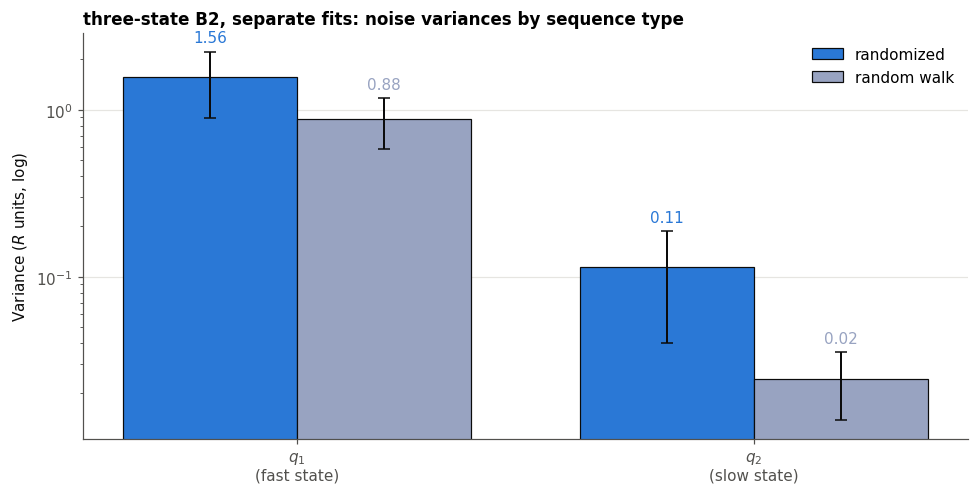

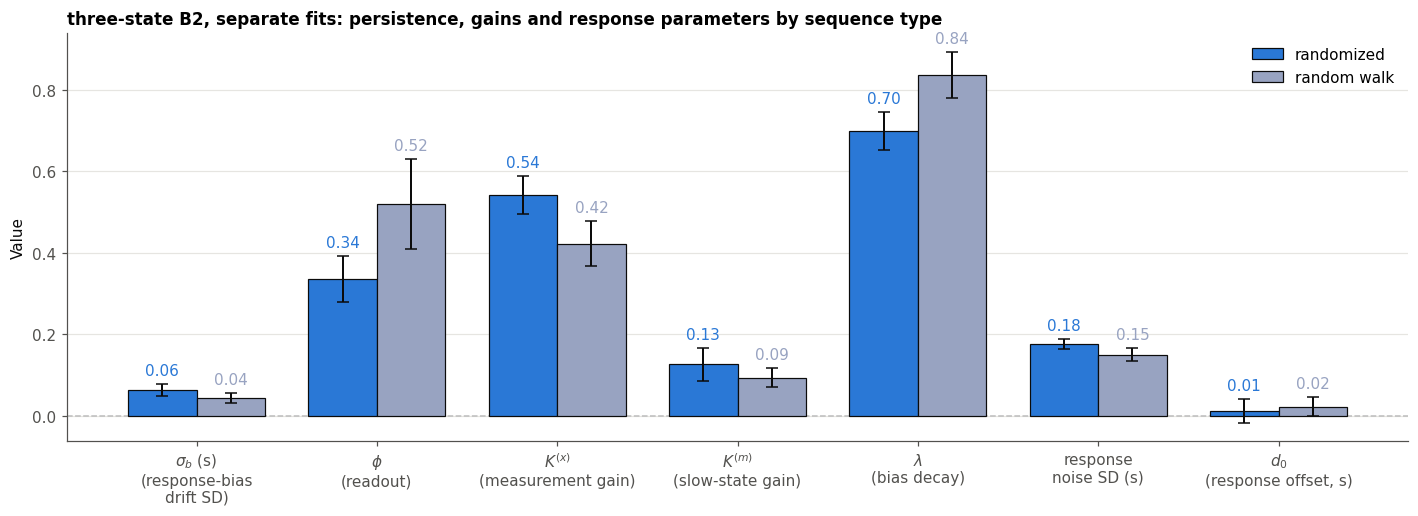

,randomized (median),random walk (median),randomized > random walk,Wilcoxon p
quantity,,,,
q1,0.8481,0.6663,8/14,0.3575
q2,0.0076,0.0037,8/14,0.3396
"σ_b (s), B2 bias drift SD",0.0466,0.0189,8/14,0.2166
λ,0.6299,0.9212,5/14,0.0906
φ,0.3696,0.5235,5/14,0.1726
K(x),0.5208,0.4541,8/14,0.0676
K(m),0.0783,0.0501,9/14,0.4263
response noise SD,0.1723,0.1244,11/14,0.0166
d0,0.0385,0.0255,8/14,0.8077


In [7]:
sequence_parameters = R.sequence_parameters(D)
R.plot_sequence_parameters(sequence_parameters)
plt.show()
display(R.sequence_tests(sequence_parameters))

**Reading.**

* <span style="color:#b71c1c">**Only the response noise differs reliably between the sequences.** It is smaller in
  random walk: median .124 against .172 s, 11 of 14 participants, $p=.017$.</span>
* The process noises $q_1$ and $q_2$, the response-bias drift $\sigma_b$ (median .047 against .019 s, $p=.22$) and
  the readout persistence $\phi$ do not differ (all $p>.17$).
* Two trends do not reach significance: a lower measurement gain in random walk ($K^{(x)}$ .45 against .52, $p=.068$)
  and a more persistent bias state ($\lambda$ .92 against .63, $p=.091$).
* This agrees with the transfer test: the change in CT and SD between the sequences needs no change in the observer.
  These separate fits are descriptive, with 6 starts each.

# What this notebook supports

1. **Partial-correlation check.** The randomized data reproduce the paper's check: mean
   $r(e_i,s_{i-1}\mid s_i)=.197$ and $r(e_i,s_i\mid s_{i-1})=-.603$ (both $p<.0001$).
2. <span style="color:#b71c1c">**CT and SD differ strongly between the sequences.** CT .455 against .096
   ($p<.001$, 14/14); SD .109 against $-.086$ ($p<.001$).</span>
3. **Paper two-state model.** It fits the randomized curves ($R^2=.963$ current, $.839$ lag 1). Frozen and applied to
   random walk, it predicts the curves less well ($R^2=.592$ and $.483$) and underestimates the random-walk CT and SD
   (CT .014 against .096, SD $-.006$ against $-.086$).
4. <span style="color:#b71c1c">**The three-state model (the Experiment 1 model, unchanged).** It fits the randomized curves ($R^2=.938$ and $.809$). Frozen, it
   predicts the random-walk curves ($R^2=.875$ and $.823$) and the random-walk CT and SD (.091 and $-.084$; paired
   tests against the data $p=.90$ and $.96$). The sequence effect on CT and SD therefore needs no parameter
   change.</span>
5. <span style="color:#b71c1c">**Held-out log score.** The three-state model beats the paper model ($+.084$, $p=.009$) and the matched
   ablation without the bias state ($+.072$, $p=.007$, 13/14).</span> Point-prediction metrics (RMSE, absolute CT and SD errors) do
   not differ significantly.
6. **In-sample AIC (randomized).** The three-state model is 8.4 units better than the two-state model on average, but only in 8 of 14
   participants ($p=.19$).
7. **Parameters by sequence type (separate fits).** Fitted separately to each sequence, only the response noise differs
   (smaller in random walk, $p=.017$). The process noises, $\phi$ and the gains do not differ significantly.
8. **What is not claimed.** No claim depends on a PPC threshold, simulated-cohort interval, static model or
   simple-iterative model.